<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_ap_trelica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V, apêndice: a treliça de uma ponte

## Forças nas barras pelo equilíbrio dos nós, e quanto elas mudam quando a ponte fica mais alta: derivadas duais de um sistema linear

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X5_dualcomplexos.ipynb](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb))

**A treliça.** Uma ponte de treliça é feita de barras retas ligadas por pinos nos **nós**. Com as cargas aplicadas só nos nós, cada barra trabalha só em tração ou compressão, com uma força axial $f_k$ (positiva em tração). O equilíbrio de cada nó dá duas equações (somas de forças em $x$ e em $y$; com números complexos, **uma** equação complexa por nó):

$$\sum_{k\ \text{no nó}} f_k\,\hat e_k+\text{reações}+\text{cargas}=0,\qquad\hat e_k=\frac{p_{\text{outro}}-p_{\text{nó}}}{|p_{\text{outro}}-p_{\text{nó}}|}.$$

Se o número de barras mais o de reações dos apoios é o dobro do número de nós, e a treliça é rígida, o sistema é quadrado e tem solução única: a treliça é **isostática**, e as forças saem de um sistema linear $\mathbf A\mathbf f=\mathbf b$.

**A pergunta de projeto.** Quanto as forças mudam se a ponte ficar mais alta? Uma treliça baixa tem barras curtas, mas forças enormes nos banzos (as barras horizontais); uma alta tem forças menores, mas diagonais longas. Há uma altura que minimiza o material. Para achá-la, é preciso a derivada das forças em relação à altura $h$.

**Derivadas duais de um sistema linear.** Montando a matriz com $h+\varepsilon$, ela vira dual: $\mathbf A_0+\varepsilon\mathbf A_1$, e o mesmo com $\mathbf b$. A solução dual $\mathbf f_0+\varepsilon\mathbf f_1$ sai de

$$\mathbf A_0\mathbf f_0=\mathbf b_0,\qquad\mathbf A_0\mathbf f_1=\mathbf b_1-\mathbf A_1\mathbf f_0,$$

**a mesma matriz** duas vezes (fatora-se uma vez só): é o que separar as partes de $(\mathbf A_0+\varepsilon\mathbf A_1)(\mathbf f_0+\varepsilon\mathbf f_1)=\mathbf b_0+\varepsilon\mathbf b_1$ dá. Os nós são números complexos, e as contas de geometria rodam com duais de partes complexas, a álgebra comutativa $\mathbb C\otimes\mathbb D$ (a mesma do apêndice do estilingue).

**O que este notebook mostra.**
1. Uma treliça de duas barras, com a resposta de livro, para conferir o montador.
2. A ponte Warren de seis painéis: forças, equilíbrio global e a derivada dual em relação à altura, conferida por diferenças finitas.
3. A altura de menor volume de material, achando o zero da derivada dual.
4. A **linha de influência** de uma diagonal: a força nela enquanto um caminhão atravessa a ponte.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

class Dual:
    """Número dual re + ε·du (notebook III(a)); re e du podem ser floats ou arrays."""
    __array_priority__ = 1000
    def __init__(self, re, du=0.0): self.re, self.du = re, du
    @staticmethod
    def _d(o): return o if isinstance(o, Dual) else Dual(o, 0.0)
    def __add__(self, o): o = Dual._d(o); return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__
    def __neg__(self): return Dual(-self.re, -self.du)
    def __sub__(self, o): return self + (-Dual._d(o))
    def __rsub__(self, o): return Dual._d(o) - self
    def __mul__(self, o): o = Dual._d(o); return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__
    def __truediv__(self, o): o = Dual._d(o); return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / o.re**2)
    def __rtruediv__(self, o): return Dual._d(o) / self
    def __repr__(self): return f"{self.re} + ε·{self.du}"

def _eleva(f, df):
    return lambda x: Dual(f(x.re), df(x.re) * x.du) if isinstance(x, Dual) else f(x)
sen = _eleva(np.sin, np.cos)
cos = _eleva(np.cos, lambda a: -np.sin(a))

from scipy.linalg import lu_factor, lu_solve

def parte(x, qual):
    if isinstance(x, Dual): return x.re if qual == 0 else x.du
    return x if qual == 0 else 0 * x

def unitario(p, q):
    """(q − p)/|q − p| para p, q complexos ou duais de partes complexas."""
    d = q - p
    if isinstance(d, Dual):
        r = np.abs(d.re); dr = (np.conj(d.re) * d.du).real / r
        return Dual(d.re / r, (d.du * r - d.re * dr) / r**2), Dual(r, dr)
    return d / abs(d), abs(d)

def resolve_trelica(nos, barras, apoios, cargas):
    """nos: lista de posições (complexas ou duais); barras: pares (i, j); apoios: lista de (nó, direção complexa unitária);
    cargas: dicionário nó → força complexa. Devolve as forças nas barras, as reações e os comprimentos (duais, se a geometria for dual)."""
    n, m, r = len(nos), len(barras), len(apoios)
    assert m + r == 2 * n, "a treliça não é isostática"
    A = [np.zeros((2 * n, m + r)), np.zeros((2 * n, m + r))]      # partes real e dual
    comprimentos = []
    for k, (i, j) in enumerate(barras):
        e, L = unitario(nos[i], nos[j]); comprimentos.append(L)
        for no, sinal in [(i, +1), (j, -1)]:
            for qual in (0, 1):
                v = sinal * parte(e, qual)
                A[qual][2 * no, k] += v.real; A[qual][2 * no + 1, k] += v.imag
    for k, (no, direcao) in enumerate(apoios):
        A[0][2 * no, m + k] = direcao.real; A[0][2 * no + 1, m + k] = direcao.imag
    b = np.zeros(2 * n)
    for no, F in cargas.items():
        b[2 * no] -= F.real; b[2 * no + 1] -= F.imag
    lu = lu_factor(A[0])
    x0 = lu_solve(lu, b)
    x1 = lu_solve(lu, -A[1] @ x0)                     # b não depende da geometria: b1 = 0
    return Dual(x0[:m], x1[:m]), Dual(x0[m:], x1[m:]), comprimentos

## 1. Duas barras, para conferir

Duas barras de comprimento igual, apoiadas em $(\pm1,0)$ e unidas no alto, em $(0,h)$, com uma carga $P$ para baixo. Cada barra é comprimida com $N=P/(2\,\mathrm{sen}\,\alpha)$, com $\alpha$ o ângulo da barra com a horizontal, $\tan\alpha=h$. A derivada em relação a $h$ também tem fórmula.

In [2]:
h0, P = 1.5, 10.0
h = Dual(h0, 1.0)
nos = [-1 + 0j, 1 + 0j, 1j * h]
barras = [(0, 2), (1, 2)]
apoios = [(0, 1 + 0j), (0, 1j), (1, 1 + 0j), (1, 1j)]
f, reacoes, _ = resolve_trelica(nos, barras, apoios, {2: -1j * P})
N_teo = lambda h: -P * np.sqrt(1 + h**2) / (2 * h)   # sen α = h/√(1+h²); compressão é negativa
dN_teo = (N_teo(h0 + 1e-6) - N_teo(h0 - 1e-6)) / 2e-6
print(f"forças: {f.re};  livro: {N_teo(h0):.6f}")
confere("duas barras: força de livro", f.re, [N_teo(h0)] * 2, tol=1e-12)
confere("duas barras: derivada dual = derivada da fórmula", f.du, [dN_teo] * 2, tol=1e-7)

forças: [-6.009252 -6.009252];  livro: -6.009252
OK   duas barras: força de livro:  diferença máxima = 1.78e-15
OK   duas barras: derivada dual = derivada da fórmula:  diferença máxima = 1.10e-10


## 2. A ponte Warren

Seis painéis de 4 m (vão de 24 m). Sete nós no tabuleiro, embaixo, e seis no alto, a uma altura $h$, ligados por diagonais em zigue-zague. Apoio fixo à esquerda (duas reações) e móvel à direita (uma, vertical): $23$ barras $+\ 3$ reações $=2\times13$ nós. Cada nó interno do tabuleiro carrega 100 kN (o peso do tabuleiro e do tráfego).

In [3]:
PAINEL, NP, CARGA = 4.0, 6, 100.0

def warren(h):
    baixo = [k * PAINEL + 0j for k in range(NP + 1)]
    alto = [(k + 0.5) * PAINEL + 1j * h for k in range(NP)]
    nos = baixo + alto
    barras = [(k, k + 1) for k in range(NP)]                                   # banzo inferior
    barras += [(NP + 1 + k, NP + 2 + k) for k in range(NP - 1)]                # banzo superior
    barras += [(k, NP + 1 + k) for k in range(NP)] + [(k + 1, NP + 1 + k) for k in range(NP)]   # diagonais
    apoios = [(0, 1 + 0j), (0, 1j), (NP, 1j)]
    return nos, barras, apoios

def cargas_tabuleiro():
    return {k: -1j * CARGA for k in range(1, NP)}

H0 = 3.0
nos, barras, apoios = warren(Dual(H0, 1.0))
f, reac, L = resolve_trelica(nos, barras, apoios, cargas_tabuleiro())
print("reações (kN):", np.round(reac.re, 6))
confere("as reações verticais somam a carga total", reac.re[1] + reac.re[2], CARGA * (NP - 1), tol=1e-9)
confere("e, por simetria, dividem-se ao meio", reac.re[1], reac.re[2], tol=1e-9)
nomes = [f"banzo inf {k}" for k in range(NP)] + [f"banzo sup {k}" for k in range(NP - 1)] + [f"diag {k}" for k in range(2 * NP)]
k_max = np.argmax(np.abs(f.re))
print(f"maior força: {nomes[k_max]}, {f.re[k_max]:+.1f} kN;  banzo inferior central {f.re[NP // 2]:+.1f} kN (tração), banzo superior central {f.re[NP + (NP - 1) // 2]:+.1f} kN (compressão)")
# o banzo inferior central confere com o momento fletor no meio do vão, dividido pela altura
M_meio = reac.re[1] * 12 - CARGA * (8 + 4)           # momento em x = 12 m (cargas em 4 e 8 m à esquerda)
# corte de Ritter: o corte que atravessa o banzo superior entre x = 10 e 14 m passa também por uma diagonal e pelo banzo inferior,
# que se encontram no nó de baixo em x = 12 m; o equilíbrio de momentos em torno desse nó envolve só o banzo superior
confere("banzo superior central = −M(12 m)/h (corte de Ritter)", f.re[NP + (NP - 1) // 2], -M_meio / H0, tol=1e-9, relativo=True)

h_df = 1e-6
f_mais = resolve_trelica(warren(H0 + h_df)[0], barras, apoios, cargas_tabuleiro())[0].re
f_menos = resolve_trelica(warren(H0 - h_df)[0], barras, apoios, cargas_tabuleiro())[0].re
confere("derivada dual das 23 forças = diferenças finitas", f.du, (f_mais - f_menos) / (2 * h_df), tol=1e-6, relativo=True)

reações (kN): [ -0. 250. 250.]
OK   as reações verticais somam a carga total:  diferença máxima = 1.14e-13
OK   e, por simetria, dividem-se ao meio:  diferença máxima = 2.84e-14
maior força: banzo sup 2, -600.0 kN;  banzo inferior central +566.7 kN (tração), banzo superior central -600.0 kN (compressão)
OK   banzo superior central = −M(12 m)/h (corte de Ritter):  diferença relativa máxima = 1.89e-16
OK   derivada dual das 23 forças = diferenças finitas:  diferença relativa máxima = 2.46e-10


## 3. A altura de menor volume

No dimensionamento mais simples, cada barra recebe a área estritamente necessária, $A_k=|f_k|/\sigma_{\text{adm}}$, e o volume de aço é

$$V(h)=\frac1{\sigma_{\text{adm}}}\sum_k|f_k(h)|\,L_k(h).$$

A derivada dual sai da mesma conta, com $|f|'=\mathrm{sinal}(f)\,f'$. A altura ótima é o zero de $V'(h)$, achado pelo método da secante sobre a derivada dual (sem diferenças finitas).

In [4]:
SIGMA = 150e3                                        # tensão admissível, kN/m² (150 MPa)

def volume(h):
    nos, barras, apoios = warren(h)
    f, _, L = resolve_trelica(nos, barras, apoios, cargas_tabuleiro())
    V = Dual(0.0, 0.0) if isinstance(h, Dual) else 0.0
    for k in range(len(barras)):
        fk = Dual(f.re[k], f.du[k]) if isinstance(h, Dual) else f.re[k]
        absf = Dual(abs(fk.re), np.sign(fk.re) * fk.du) if isinstance(h, Dual) else abs(fk)
        V = V + absf * L[k]
    return V / SIGMA

dV = lambda h: volume(Dual(h, 1.0)).du
a_, b_ = 2.0, 6.0
for it in range(30):
    c_ = b_ - dV(b_) * (b_ - a_) / (dV(b_) - dV(a_))
    a_, b_ = b_, c_
    if abs(b_ - a_) < 1e-12: break
h_otimo = b_
print(f"altura ótima: {h_otimo:.6f} m  (h/vão = {h_otimo / 24:.4f});  volume {volume(h_otimo):.5f} m³  ({it + 1} iterações da secante)")
grade = np.linspace(1.5, 8, 2601)
vols = np.array([volume(h) for h in grade])
confere("a varredura densa encontra o mesmo mínimo", grade[np.argmin(vols)], h_otimo, tol=grade[1] - grade[0])
confere("a derivada dual do volume = diferenças finitas", dV(4.0), (volume(4.0 + 1e-6) - volume(4.0 - 1e-6)) / 2e-6, tol=1e-6, relativo=True)

altura ótima: 5.925463 m  (h/vão = 0.2469);  volume 0.14221 m³  (6 iterações da secante)


OK   a varredura densa encontra o mesmo mínimo:  diferença máxima = 4.63e-04
OK   a derivada dual do volume = diferenças finitas:  diferença relativa máxima = 4.42e-10


## 4. A linha de influência de uma diagonal

Um caminhão (uma carga de 300 kN) atravessa a ponte. Quando ele está entre dois nós do tabuleiro, o tabuleiro (uma viga simples entre os nós) reparte a carga entre esses dois nós, proporcionalmente à distância. A força numa barra, em função da posição $x$ do caminhão, é a **linha de influência** da barra: os engenheiros a usam para saber onde pôr o caminhão para o pior caso. Aqui o parâmetro dual é $x$, e a derivada dual dá a inclinação da linha.

diag 1 (com h = 3.0 m): força máxima -240.4 kN com o caminhão em x = 8.0 m;  a força troca de sinal em x ≈ 4.8 m (e volta a zero no apoio, em 24 m)
OK   a derivada dual da linha de influência = diferenças finitas:  diferença relativa máxima = 1.48e-10


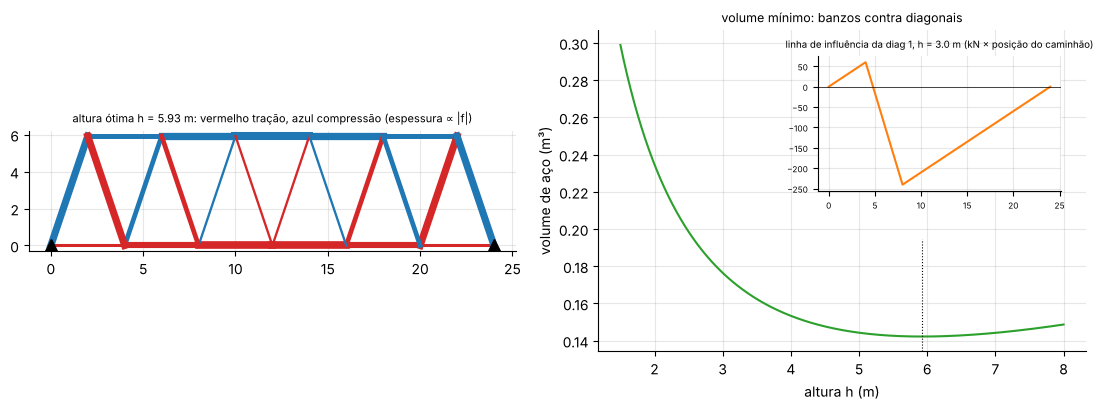

In [5]:
def cargas_caminhao(x, P=300.0):
    k = int(np.clip(np.floor((x.re if isinstance(x, Dual) else x) / PAINEL), 0, NP - 1))
    s = (x - k * PAINEL) / PAINEL                    # fração do painel (dual, se x for dual)
    return k, s, P

def forca_barra(x, barra):
    nos, barras, apoios = warren(H0)
    k, s, P = cargas_caminhao(x)
    # a carga é linear nas forças: resolve com uma carga unitária em cada um dos dois nós e combina
    f_k = resolve_trelica(nos, barras, apoios, {k: -1j * P})[0].re[barra]
    f_k1 = resolve_trelica(nos, barras, apoios, {k + 1: -1j * P})[0].re[barra]
    return (1 - s) * f_k + s * f_k1

DIAG = NP + (NP - 1) + 1                              # a segunda diagonal (subindo do nó 1)
xs = np.linspace(0, 24, 241)
linha = np.array([forca_barra(x, DIAG) for x in xs])
x_pior = xs[np.argmax(np.abs(linha))]
troca = xs[1:][(linha[:-1] > 0) & (linha[1:] <= 0)]      # de tração para compressão
print(f"{nomes[DIAG]} (com h = {H0} m): força máxima {linha[np.argmax(np.abs(linha))]:+.1f} kN com o caminhão em x = {x_pior:.1f} m;  "
      f"a força troca de sinal em x ≈ {troca[0]:.1f} m (e volta a zero no apoio, em 24 m)")
inclinacao = forca_barra(Dual(10.0, 1.0), DIAG).du
confere("a derivada dual da linha de influência = diferenças finitas", inclinacao, (forca_barra(10.0 + 1e-6, DIAG) - forca_barra(10.0 - 1e-6, DIAG)) / 2e-6, tol=1e-6, relativo=True)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax = axs[0]
nos_n = warren(h_otimo)[0]
f_n = resolve_trelica(nos_n, barras, apoios, cargas_tabuleiro())[0].re
fmax = np.abs(f_n).max()
for k, (i, j) in enumerate(barras):
    cor = "C3" if f_n[k] > 0 else "C0"
    ax.plot([nos_n[i].real, nos_n[j].real], [nos_n[i].imag, nos_n[j].imag], color=cor, lw=0.8 + 5 * abs(f_n[k]) / fmax)
ax.plot([0, 24], [0, 0], "k^", ms=9)
ax.set_aspect("equal"); ax.set_title(f"altura ótima h = {h_otimo:.2f} m: vermelho tração, azul compressão (espessura ∝ |f|)", fontsize=8)
ax = axs[1]
ax.plot(grade, vols, "C2-"); ax.axvline(h_otimo, ymax=0.35, color="k", ls=":", lw=0.8)
ax.set_xlabel("altura h (m)"); ax.set_ylabel("volume de aço (m³)"); ax.set_title("volume mínimo: banzos contra diagonais", fontsize=9)
ins = ax.inset_axes([0.45, 0.5, 0.5, 0.42])
ins.plot(xs, linha, "C1-"); ins.axhline(0, color="k", lw=0.5); ins.set_title(f"linha de influência da {nomes[DIAG]}, h = {H0} m (kN × posição do caminhão)", fontsize=7)
ins.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

**Leitura.** O montador acerta a treliça de duas barras (força e derivada de livro) e, na ponte, as reações e o corte de Ritter: o banzo superior central, comprimido com 600 kN, é exatamente o momento fletor no meio do vão dividido pela altura, como numa viga em que os banzos fazem o papel das fibras de cima e de baixo. As 23 derivadas duais $\partial f_k/\partial h$ concordam com as diferenças finitas em 10 algarismos, e custam uma segunda solução com a **mesma** fatoração LU.

O volume tem um mínimo raso em $h\approx5{,}93$ m, cerca de um quarto do vão: abaixo disso os banzos (força $\propto1/h$) pesam demais, acima as diagonais ficam longas. A secante sobre a derivada dual chega lá em 6 iterações, e uma varredura de 2601 alturas confirma. O mínimo é **raso**: de 5 a 7 m o volume muda menos de 2%, e é por isso que, na prática, a altura é decidida por outras coisas (gabarito de navegação, flambagem, estética), e o que se aproveita da conta é saber que $h/\text{vão}$ de 1/8 (comum em pontes reais, por outros motivos) custa uns 24% a mais de aço que o ótimo deste modelo simples.

A linha de influência da diagonal mostra o que uma carga só não mostra: com o caminhão no primeiro painel, a diagonal é tracionada; quando ele passa de uns 5 m, ela vira compressão, máxima (240 kN) com o caminhão no nó de 8 m. Uma barra que troca de sinal tem de ser dimensionada para os dois casos, e para a flambagem.

## Exercícios

1. **Flambagem.** Uma barra comprimida pode flambar antes de atingir $\sigma_{\text{adm}}$: a carga crítica de Euler é $\pi^2EI/L^2$, e, para perfis de mesma forma, o momento de inércia $I$ é proporcional a $A^2$. Dimensione as barras comprimidas pelo maior dos dois critérios (resistência e flambagem). A altura ótima sobe ou desce? As diagonais comprimidas, que são longas, passam a pesar mais?
2. **Uma segunda derivada.** Com duais "hiper-duais" ($\varepsilon_1,\varepsilon_2$, com $\varepsilon_1\varepsilon_2\neq0$), dá para obter $V''(h)$ exato e usar Newton no lugar da secante. Implemente-os (são quatro componentes, como os dual-complexos: que álgebra é essa?).
3. **Pratt e Howe.** Monte as treliças Pratt (montantes verticais, diagonais descendo para o centro) e Howe (diagonais subindo para o centro) com o mesmo vão. Em qual delas as diagonais trabalham em tração? Por que os engenheiros preferem diagonais tracionadas?